# Validate rho and missing-proton masses after momentum correction

Run top to bottom in the `clas12-eloss-ml` environment, from the project directory.
Only the final corrected Parquet is read. The current path comes from configuration cell 2 of
`XBDT_inference_all_events_was_corrected.ipynb`; no inference or training is rerun.

Species use **only `pid_gen`**. An event is keyed by **`(file_id, event)`** and must contain
exactly one **usable** electron, proton, π+, and π−. A usable row has `was_corrected == 1`
and finite generated, original reconstructed, and corrected three-momenta. Duplicate usable
candidates make an event ambiguous; no arbitrary candidate is chosen. No trigger, `pid_rec`,
or additional detector selection is imposed. The measured proton is required in the common
sample even though the missing-proton expression deliberately omits it.

All six distributions use one event sample. Nonfinite derived quantities or negative squared
masses in **any** of the six quantities exclude the event from **all** six distributions;
counts are reported before that common cut. No absolute value or clipping of negative mass
squared is used. This common cut can affect the tails and its size must be checked.

Two additional cells plot the **proton** missing-mass spectrum in Q² bins and in −t bins.
Both partition the same common sample using **corrected reconstructed kinematics** for both Q² and −t,
so bin migration cannot change the sample between before/after/generated overlays.
The default four bins contain approximately equal numbers of events; each cell exposes its
bin edges for manual adjustment. A separate final cell shows the corrected reconstructed Q² and −t
distributions with the same bin edges marked by vertical dashed lines.
No pion missing-mass plots are included.


In [90]:
from pathlib import Path
import tempfile
import warnings

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
from IPython.display import display
from scipy.optimize import curve_fit, OptimizeWarning

CORRECTED_PARQUET_PATH = Path(
    "parquet/hepgen_uni_z_ALL_energy_loss_corrected_all_events.parquet"
).resolve()
# Project source: older/rho_zero_tests.ipynb, inclusive-kinematics cell.
# This is total incident electron energy, along +z; retain the electron rest mass.
BEAM_ENERGY_GEV = 10.6
MASS_GEV = {"e": 0.00051099895000, "p": 0.9382720813,
            "pip": 0.13957039, "pim": 0.13957039}
PIDS = {"e": 11, "p": 2212, "pip": 211, "pim": -211}
STATES = {"generated": "gen", "before": "rec_uncorrected", "after": "rec"}
MOMENTUM_COLUMNS = [f"p{axis}_{suffix}" for suffix in STATES.values() for axis in "xyz"]
REQUIRED_COLUMNS = {"file_id", "event", "pid_gen", "was_corrected", *MOMENTUM_COLUMNS,
                    "p_rec", "p_rec_uncorrected"}

# DuckDB uses a temporary on-disk database and may spill joins/grouping to disk.
# Python only receives selected events in batches, then retains scalar observable arrays.
DUCKDB_MEMORY_LIMIT = "1GB"
EVENT_BATCH_SIZE = 25_000
RHO_BINS = np.linspace(0.25, 1.50, 251)
MISSING_BINS = np.linspace(0.8, 1.20, 401)
RHO_FIT_RANGE = (0.7, 0.85)
MISSING_FIT_RANGE = (0.92,  0.96)

In [91]:
if not CORRECTED_PARQUET_PATH.is_file():
    raise FileNotFoundError(CORRECTED_PARQUET_PATH)
parquet_file = pq.ParquetFile(CORRECTED_PARQUET_PATH)
schema = parquet_file.schema_arrow
missing_columns = REQUIRED_COLUMNS - set(schema.names)
if missing_columns:
    raise ValueError(f"Missing columns: {sorted(missing_columns)}")
print(f"Input: {CORRECTED_PARQUET_PATH}")
print(f"Rows: {parquet_file.metadata.num_rows:,}; row groups: {parquet_file.num_row_groups:,}")
print(f"Beam: {BEAM_ENERGY_GEV} GeV, +z; source: older/rho_zero_tests.ipynb")
print("Target: proton at rest; all energies are constructed from three-momenta and masses.")
display(pd.DataFrame({"column": sorted(REQUIRED_COLUMNS),
                      "type": [str(schema.field(c).type) for c in sorted(REQUIRED_COLUMNS)]}))

scratch = tempfile.TemporaryDirectory(prefix="rho_mass_validation_")
con = duckdb.connect(str(Path(scratch.name) / "validation.duckdb"))
con.execute(f"SET memory_limit = '{DUCKDB_MEMORY_LIMIT}'")
con.execute("SET threads = 2")
con.execute("SET preserve_insertion_order = false")
spill_path = str(Path(scratch.name) / "spill").replace("'", "''")
con.execute(f"SET temp_directory = '{spill_path}'")
source_sql = "read_parquet('" + CORRECTED_PARQUET_PATH.as_posix().replace("'", "''") + "')"

Input: /Users/aleksandr.bulgakov/Desktop/work/BNL_ELoss_regression/parquet/hepgen_uni_z_ALL_energy_loss_corrected_all_events.parquet
Rows: 79,680,000; row groups: 409
Beam: 10.6 GeV, +z; source: older/rho_zero_tests.ipynb
Target: proton at rest; all energies are constructed from three-momenta and masses.


,column,type
0,event,int64
1,file_id,int32
2,p_rec,float
3,p_rec_uncorrected,float
4,pid_gen,int32
5,px_gen,float
6,px_rec,float
7,px_rec_uncorrected,float
8,py_gen,float
9,py_rec,float


## Select complete, unambiguous corrected events

Grouping is global across the entire Parquet, so events may cross row-group or batch boundaries.
The counts below distinguish duplicate corrected candidates from duplicate **usable** candidates.
The exclusive rejection categories give ambiguity priority over incompleteness. A duplicate
corrected row that fails the finite-component requirement is not a usable candidate.
`MAX` is used for pivoting only after uniqueness has been established, never for resolving duplicates.

In [92]:
def create_event_tables(connection, source):
    finite_sql = " AND ".join(f"COALESCE(isfinite({c}), FALSE)" for c in MOMENTUM_COLUMNS)
    usable_sql = f"(was_corrected = 1 AND pid_gen IN (11, 2212, 211, -211) AND {finite_sql})"
    count_fields = []
    for name, pid in PIDS.items():
        count_fields += [
            f"count(*) FILTER (WHERE pid_gen = {pid} AND was_corrected = 1) AS corrected_{name}",
            f"count(*) FILTER (WHERE pid_gen = {pid} AND {usable_sql}) AS n_{name}",
        ]
    connection.execute(f"""
        CREATE OR REPLACE TABLE event_stats AS
        SELECT file_id, event, {', '.join(count_fields)}
        FROM {source}
        WHERE file_id IS NOT NULL AND event IS NOT NULL
        GROUP BY file_id, event
    """)
    unique_sql = " AND ".join(f"n_{name} = 1" for name in PIDS)
    connection.execute(f"""
        CREATE OR REPLACE TABLE selected_keys AS
        SELECT file_id, event FROM event_stats WHERE {unique_sql}
    """)
    pivots = [
        f"max(CAST(r.{column} AS DOUBLE)) FILTER (WHERE r.pid_gen = {pid}) AS {name}_{column}"
        for name, pid in PIDS.items() for column in MOMENTUM_COLUMNS
    ]
    connection.execute(f"""
        CREATE OR REPLACE TABLE selected_events AS
        SELECT r.file_id, r.event, {', '.join(pivots)}
        FROM {source} r INNER JOIN selected_keys k USING (file_id, event)
        WHERE {usable_sql}
        GROUP BY r.file_id, r.event
    """)

create_event_tables(con, source_sql)
raw_audit = con.execute(f"""
    SELECT count(*) AS rows,
           count(*) FILTER (WHERE file_id IS NULL OR event IS NULL) AS null_key_rows,
           count(*) FILTER (WHERE was_corrected = 1) AS corrected_rows,
           count(*) FILTER (WHERE was_corrected IS NULL OR was_corrected NOT IN (0, 1)) AS invalid_flags
    FROM {source_sql}
""").df()
display(raw_audit)
assert int(raw_audit.iloc[0]["rows"]) == parquet_file.metadata.num_rows
assert int(raw_audit.iloc[0]["invalid_flags"]) == 0, "Invalid correction flags"
ambiguous = " OR ".join(f"n_{name} > 1" for name in PIDS)
incomplete = " OR ".join(f"n_{name} = 0" for name in PIDS)
corrected_dup = " OR ".join(f"corrected_{name} > 1" for name in PIDS)
selection_counts = con.execute(f"""
    SELECT count(*) AS events_with_valid_keys,
        count(*) FILTER (WHERE {corrected_dup}) AS duplicate_corrected_candidates,
        count(*) FILTER (WHERE {ambiguous}) AS rejected_ambiguous,
        count(*) FILTER (WHERE ({incomplete}) AND NOT ({ambiguous})) AS rejected_incomplete_only,
        count(*) FILTER (WHERE ({incomplete}) AND ({ambiguous})) AS incomplete_and_ambiguous,
        (SELECT count(*) FROM selected_keys) AS selected_complete_unique
    FROM event_stats
""").df()
display(selection_counts.T.rename(columns={0: "events"}))
s = selection_counts.iloc[0]
assert s.events_with_valid_keys == s.rejected_ambiguous + s.rejected_incomplete_only + s.selected_complete_unique
N_SELECTED = int(s.selected_complete_unique)
assert N_SELECTED == con.execute("SELECT count(*) FROM selected_events").fetchone()[0]
if N_SELECTED == 0:
    raise RuntimeError("No complete unique usable corrected events")
per_species = con.execute("SELECT " + ", ".join(
    f"sum(corrected_{name}) AS corrected_{name}, sum(n_{name}) AS usable_{name}, "
    f"count(*) FILTER (WHERE n_{name} > 1) AS ambiguous_{name}" for name in PIDS
) + " FROM event_stats").df()
display(per_species.T.rename(columns={0: "rows / events (ambiguous)"}))
print("Example ambiguous event keys and candidate counts (up to 10):")
display(con.execute(f"SELECT * FROM event_stats WHERE {ambiguous} ORDER BY file_id, event LIMIT 10").df())

,rows,null_key_rows,corrected_rows,invalid_flags
0,79680000,0,21595225,0


,events
events_with_valid_keys,19920000
duplicate_corrected_candidates,0
rejected_ambiguous,0
rejected_incomplete_only,19556381
incomplete_and_ambiguous,0
selected_complete_unique,363619


,rows / events (ambiguous)
corrected_e,5024761.0
usable_e,5024761.0
ambiguous_e,0.0
corrected_p,4011578.0
usable_p,4011578.0
ambiguous_p,0.0
corrected_pip,7892848.0
usable_pip,7892848.0
ambiguous_pip,0.0
corrected_pim,4666038.0


Example ambiguous event keys and candidate counts (up to 10):


,file_id,event,corrected_e,n_e,corrected_p,n_p,corrected_pip,n_pip,corrected_pim,n_pim


## Construct four-vectors and both requested squared masses

Use metric $P^2=E^2-\mathbf p^2$ and $c=1$. For each state, energies are
$E=\sqrt{p_x^2+p_y^2+p_z^2+m^2}$, using the physical mass of that species.
The incident electron has $P_b=(E_b,0,0,\sqrt{E_b^2-m_e^2})$ and the
stationary target has $P_t=(m_p,0,0,0)$.

- $M_{\pi\pi}^2=(P_{\pi^+}+P_{\pi^-})^2$.
- **Missing proton:** $M_{X,p}^2=(P_b+P_t-P_{e'}-P_{\pi^+}-P_{\pi^-})^2$,
  expected near $m_p^2$. The outgoing proton is deliberately omitted.
- **Fully exclusive:** $M_X^2=(P_b+P_t-P_{e'}-P_{p'}-P_{\pi^+}-P_{\pi^-})^2$,
  for $ep\to e'p'\pi^+\pi^-X$, expected near zero. This distinct quantity is
  not used as the requested missing-proton mass diagnostic.

**Electron Q² calculation (GeV²):**
\[
Q^2=-(P_b-P_{e'})^2
=2\left(E_b E_{e'}-p_{b,z}p_{e',z}-m_e^2\right),
\quad E_{e'}=\sqrt{p_x^2+p_y^2+p_z^2+m_e^2}.
\]
`electron_q2_from_components` below implements this explicitly. For corrected Q² it uses
only the electron's corrected `px_rec`, `py_rec`, `pz_rec`, with a 10.6 GeV beam along +z.
Every event is cross-checked against direct four-vector subtraction. The cell also reports
the difference from the older massless-electron formula,
$Q^2\simeq2E_b(|\mathbf p_{e'}|-p_{e',z})=4E_b|\mathbf p_{e'}|\sin^2(\theta_{e'}/2)$.


In [93]:
def minkowski_square(v):
    return v[:, 0]**2 - np.sum(v[:, 1:]**2, axis=1)

BEAM_P4 = np.array([BEAM_ENERGY_GEV, 0.0, 0.0,
                    np.sqrt(BEAM_ENERGY_GEV**2 - MASS_GEV["e"]**2)])
TARGET_P4 = np.array([MASS_GEV["p"], 0.0, 0.0, 0.0])
INITIAL_P4 = BEAM_P4 + TARGET_P4


def electron_q2_from_components(px_e, py_e, pz_e):
    """Q² from the outgoing ELECTRON three-momentum, with metric (+, -, -, -)."""
    m_e = MASS_GEV["e"]
    electron_energy = np.sqrt(px_e**2 + py_e**2 + pz_e**2 + m_e**2)
    beam_pz = np.sqrt(BEAM_ENERGY_GEV**2 - m_e**2)
    # Exact expansion of Q² = -(P_beam - P_e')², in GeV².
    return 2.0 * (BEAM_ENERGY_GEV * electron_energy - beam_pz * pz_e - m_e**2)


q2_crosschecks = {
    state: {"events_checked": 0, "max_exact_vs_fourvector_GeV2": 0.0,
            "max_exact_vs_old_massless_GeV2": 0.0,
            "max_massless_vs_angle_GeV2": 0.0}
    for state in STATES
}

def squared_observables(batch):
    result = {}
    for state, suffix in STATES.items():
        vectors = {}
        for species in PIDS:
            p3 = np.column_stack([
                batch.column(batch.schema.get_field_index(f"{species}_p{axis}_{suffix}"))
                     .to_numpy(zero_copy_only=False) for axis in "xyz"
            ]).astype(np.float64, copy=False)
            energy = np.sqrt(np.sum(p3**2, axis=1) + MASS_GEV[species]**2)
            vectors[species] = np.column_stack([energy, p3])
        result[("rho", state)] = minkowski_square(vectors["pip"] + vectors["pim"])
        result[("missing_proton", state)] = minkowski_square(
            INITIAL_P4 - vectors["e"] - vectors["pip"] - vectors["pim"]
        )
        # Q² = -(k-k')² and t = (p_target-p')², with the same physical masses.
        # Store positive -t for the bin labels. No new kinematic cuts are imposed.
        # state="after" reads e_px_rec/e_py_rec/e_pz_rec: CORRECTED electron momenta.
        # state="before" reads the *_rec_uncorrected columns; generated reads *_gen.
        px_e, py_e, pz_e = vectors["e"][:, 1:].T
        q2_exact = electron_q2_from_components(px_e, py_e, pz_e)
        q2_fourvector = -minkowski_square(BEAM_P4 - vectors["e"])
        electron_p = np.sqrt(px_e**2 + py_e**2 + pz_e**2)
        q2_old_massless = 2.0 * BEAM_ENERGY_GEV * (electron_p - pz_e)
        electron_theta = np.arctan2(np.hypot(px_e, py_e), pz_e)
        q2_angle_massless = 4.0 * BEAM_ENERGY_GEV * electron_p * np.sin(electron_theta / 2.0)**2
        np.testing.assert_allclose(q2_exact, q2_fourvector, rtol=1e-10, atol=1e-10)
        np.testing.assert_allclose(q2_old_massless, q2_angle_massless, rtol=1e-10, atol=1e-10)
        checks = q2_crosschecks[state]
        checks["events_checked"] += len(q2_exact)
        for name, differences in [
            ("max_exact_vs_fourvector_GeV2", q2_exact - q2_fourvector),
            ("max_exact_vs_old_massless_GeV2", q2_exact - q2_old_massless),
            ("max_massless_vs_angle_GeV2", q2_old_massless - q2_angle_massless),
        ]:
            checks[name] = max(checks[name], float(np.max(np.abs(differences))))
        result[("Q2", state)] = q2_exact
        result[("minus_t", state)] = -minkowski_square(TARGET_P4 - vectors["p"])
    return result

BASE_OBSERVABLES = ("rho", "missing_proton")
KINEMATIC_OBSERVABLES = ("Q2", "minus_t")
chunks = {(observable, state): [] for observable in BASE_OBSERVABLES + KINEMATIC_OBSERVABLES
          for state in STATES}
reader = con.execute("SELECT * FROM selected_events").to_arrow_reader(EVENT_BATCH_SIZE)
for batch in reader:
    for key, values in squared_observables(batch).items():
        chunks[key].append(values)
mass2 = {key: np.concatenate(parts) for key, parts in chunks.items()}
del chunks, reader
assert all(values.size == N_SELECTED for values in mass2.values())
common_mass_mask = np.ones(N_SELECTED, dtype=bool)
quality_rows = []
for (observable, state), values in mass2.items():
    # Keep the original common sample: kinematic binning does not impose new cuts.
    if observable not in BASE_OBSERVABLES:
        continue
    finite = np.isfinite(values)
    nonnegative = values >= 0
    quality_rows.append({"observable": observable, "state": state, "input_events": len(values),
                         "nonfinite_M2": int((~finite).sum()),
                         "negative_M2": int((finite & ~nonnegative).sum())})
    common_mass_mask &= finite & nonnegative
quality = pd.DataFrame(quality_rows)
display(quality)
N_COMMON = int(common_mass_mask.sum())
print(f"Common mass-domain cut: {N_SELECTED - N_COMMON:,} rejected; {N_COMMON:,} retained")
if N_COMMON == 0:
    raise RuntimeError("No events survive the common finite/nonnegative squared-mass cut")
masses = {key: np.sqrt(values[common_mass_mask]) for key, values in mass2.items()
          if key[0] in BASE_OBSERVABLES}
# Preserve exact positional alignment with the six mass arrays, including the common cut.
event_kinematics = {key: values[common_mass_mask] for key, values in mass2.items()
                    if key[0] in KINEMATIC_OBSERVABLES}
assert all(len(values) == N_COMMON and np.isfinite(values).all()
           for values in event_kinematics.values())
comparison_counts = pd.DataFrame([
    {"observable": observable, **{state: len(masses[(observable, state)]) for state in STATES}}
    for observable in ("rho", "missing_proton")
])
display(comparison_counts)
assert all(len(values) == N_COMMON for values in masses.values())
assert all(np.isfinite(values).all() for values in masses.values())
print(f"Confirmed identical event identities and counts in all six arrays: {N_COMMON:,}")
q2_formula_validation = pd.DataFrame.from_dict(q2_crosschecks, orient="index")
print("Q² formula validation on all complete corrected events before the common mass-domain cut:")
with pd.option_context("display.max_columns", None, "display.width", 180):
    display(q2_formula_validation)
print("Corrected Q² uses only the corrected outgoing-electron px_rec, py_rec, pz_rec.")
# The common mask is applied once at the same positions for all arrays.
del mass2, common_mass_mask
con.close()
scratch.cleanup()

,observable,state,input_events,nonfinite_M2,negative_M2
0,rho,generated,363619,0,0
1,rho,before,363619,0,0
2,rho,after,363619,0,0
3,missing_proton,generated,363619,0,0
4,missing_proton,before,363619,0,677
5,missing_proton,after,363619,0,732


Common mass-domain cut: 732 rejected; 362,887 retained


,observable,generated,before,after
0,rho,362887,362887,362887
1,missing_proton,362887,362887,362887


Confirmed identical event identities and counts in all six arrays: 362,887
Q² formula validation on all complete corrected events before the common mass-domain cut:


,events_checked,max_exact_vs_fourvector_GeV2,max_exact_vs_old_massless_GeV2,max_massless_vs_angle_GeV2
generated,363619,4.951595e-14,9.493895e-07,2.775558e-14
before,363619,5.306866e-14,9.059887e-07,2.819966e-14
after,363619,5.107026e-14,8.993787e-07,2.819966e-14


Corrected Q² uses only the corrected outgoing-electron px_rec, py_rec, pz_rec.


## Fit prescription and plotting

Use the same displayed bins and fixed central fit window for before and after:
the bounds are configured by `RHO_FIT_RANGE` and `MISSING_FIT_RANGE` above.
The binned proton diagnostics reuse `MISSING_BINS` and `MISSING_FIT_RANGE` in every bin.
Fit $A\exp[-(x-\mu)^2/(2\sigma^2)]$ to histogram bin centers by weighted
least squares, with errors $\sqrt{\max(n,1)}$, including empty bins, and
`absolute_sigma=True`. Fit errors are the square roots of the covariance diagonal;
report $\chi^2$/ndf to expose poor Gaussian descriptions. Failed, boundary-limited,
or unresolved fits are reported, without a different fallback estimator.

The rho Gaussian is only a **descriptive peak-position/width comparison**;
its sigma is **not the intrinsic rho width**. Fit results depend on this stated window.
The generated missing-proton peak is never fitted: an effectively delta-function
reference does not have a meaningful histogram Gaussian width. Its mean and RMS are printed.
Histogram underflow/overflow are reported without removing events from the common sample.
Both panels share bins, x range, and a linear y scale. For all missing-particle plots,
the shared y maximum is 1.15 times the larger before/after reconstructed histogram peak;
the generated spike may extend beyond the visible range. The rho scale includes all peaks.

Large $\chi^2$/ndf signals that a Gaussian does not describe the peak well. The covariance
errors are formal statistical fit errors, without line-shape or fit-window systematic uncertainties.
The generated missing-proton mean is compared with the physical proton mass below; a shift
in this reference is a check on the production/beam conventions, independent of the ML correction.

In [107]:
def gaussian(x, amplitude, mean, sigma):
    return amplitude * np.exp(-0.5 * ((x - mean) / sigma)**2)


def fit_peak(values, bins, fit_range):
    counts, _ = np.histogram(values, bins=bins)
    centers = (bins[:-1] + bins[1:]) / 2
    use = (centers >= fit_range[0]) & (centers <= fit_range[1])
    x, y = centers[use], counts[use].astype(float)
    width = bins[1] - bins[0]
    if y.sum() < 50 or np.count_nonzero(y) < 5:
        return {"status": "insufficient populated peak bins"}
    mean0 = np.sum(x*y) / y.sum()
    sigma0 = np.sqrt(np.sum(y*(x-mean0)**2) / y.sum())
    lower = [0.0, fit_range[0], width / 2]
    upper = [np.inf, fit_range[1], fit_range[1] - fit_range[0]]
    try:
        with warnings.catch_warnings():
            warnings.simplefilter("error", OptimizeWarning)
            parameters, covariance = curve_fit(
                gaussian, x, y, p0=[y.max(), mean0, max(sigma0, width)],
                sigma=np.sqrt(np.maximum(y, 1)), absolute_sigma=True,
                bounds=(lower, upper), maxfev=50_000,
            )
        errors = np.sqrt(np.diag(covariance))
        if not np.isfinite(parameters).all() or not np.isfinite(errors).all():
            raise ValueError("nonfinite parameters or covariance")
        if (np.isclose(parameters[1:], lower[1:], rtol=1e-4, atol=1e-8).any()
                or np.isclose(parameters[1:], upper[1:], rtol=1e-4, atol=1e-8).any()):
            raise ValueError("fit reaches parameter boundary")
        chi2 = np.sum((y - gaussian(x, *parameters))**2 / np.maximum(y, 1))
        return {"status": "ok", "parameters": parameters, "errors": errors,
                "chi2_ndf": chi2 / (len(x) - 3)}
    except (RuntimeError, ValueError, OptimizeWarning) as error:
        return {"status": str(error)}


def fit_annotation(label, result, units="GeV/$c^2$"):
    if result["status"] != "ok":
        return f"{label}: fit unavailable ({result['status']})"
    p, err = result["parameters"], result["errors"]
    return (f"{label} Gaussian [{units}]:\n"
            rf"$\mu={p[1]:.5f}\pm{err[1]:.5f}$" + "\n" +
            rf"$\sigma={p[2]:.5f}\pm{err[2]:.5f}$" + "\n" +
            rf"$\chi^2/\mathrm{{ndf}}={result['chi2_ndf']:.2f}$")

fit_records = []

def plot_comparison(observable, bins, fit_range, title, xlabel, fit_generated,
                    units="GeV/$c^2$", selected_masses=None):
    sample = masses if selected_masses is None else selected_masses
    n_events = len(sample[(observable, "generated")])
    assert all(len(sample[(observable, state)]) == n_events for state in STATES)
    gen = sample[(observable, "generated")]
    gen_counts, _ = np.histogram(gen, bins)
    gen_fit = fit_peak(gen, bins, fit_range) if fit_generated else None
    fits = {state: fit_peak(sample[(observable, state)], bins, fit_range)
            for state in ("before", "after")}
    reco_ymax = max(np.histogram(sample[(observable, state)], bins)[0].max()
                    for state in ("before", "after"))
    # Resolve the reconstructed peaks; the generated missing-mass spike may be clipped.
    ymax = reco_ymax if observable.startswith("missing_") else max(gen_counts.max(), reco_ymax)
    fig, axes = plt.subplots(1, 2, figsize=(16, 6.5), sharex=True, sharey=True)
    for ax, state in zip(axes, ("before", "after")):
        rec = sample[(observable, state)]
        ax.hist(gen, bins=bins, histtype="step", color="blue", linewidth=1.5,
                label=f"Generated (N={n_events:,})")
        ax.hist(rec, bins=bins, histtype="step", color="black", linewidth=1.4,
                label=f"{'Original' if state == 'before' else 'Corrected'} reco (N={n_events:,})")
        notes = [fit_annotation("Reco", fits[state], units)]
        fit_x = np.linspace(*fit_range, 500)
        for label, result, color in [("Reco Gaussian", fits[state], "red"),
                                     ("Generated Gaussian", gen_fit, "blue")]:
            if result is not None and result["status"] == "ok":
                ax.plot(fit_x, gaussian(fit_x, *result["parameters"]), color=color,
                        linestyle="--", linewidth=1.5, label=label)
        if gen_fit is not None:
            notes.append(fit_annotation("Generated", gen_fit, units))
        else:
            notes.append("Generated reference: no Gaussian fit")
        ax.text(0.98, 0.96, "\n\n".join(notes), transform=ax.transAxes, va="top", ha="right",
                fontsize=9, bbox={"facecolor": "white", "alpha": 0.90, "edgecolor": "0.8"})
        ax.set(xlim=(bins[0], bins[-1]), ylim=(0, 1.15 * max(ymax, 1)),
               xlabel=xlabel, ylabel=f"Events / {bins[1]-bins[0]:.4f} {units}",
               title="Original reconstruction" if state == "before" else "Corrected reconstruction")
        ax.set_yscale("linear")
        if observable == "rho":
            ax.axvline(0.775, color="tab:green", linestyle="--", linewidth=1.5,
                       label=r"$m_{\rho}=0.775$ GeV/$c^2$")
        ax.legend(loc="upper left", fontsize=8)
        ax.grid(alpha=0.2)
    fig.suptitle(
    title,
    fontsize=30,
    fontweight="bold"
)
    fig.tight_layout()
    plt.show()
    for state in STATES:
        values = sample[(observable, state)]
        print(f"{observable}, {state}: N={len(values):,}; "
              f"below display={np.count_nonzero(values < bins[0]):,}; "
              f"above display={np.count_nonzero(values > bins[-1]):,}")
        result = gen_fit if state == "generated" else fits[state]
        record = {"observable": observable, "state": state,
                  "status": "not fitted (delta-like reference)" if result is None else result["status"]}
        if result is not None and result["status"] == "ok":
            record.update(mu=result["parameters"][1], mu_error=result["errors"][1],
                          sigma=result["parameters"][2], sigma_error=result["errors"][2],
                          chi2_ndf=result["chi2_ndf"])
        fit_records.append(record)
    return fig

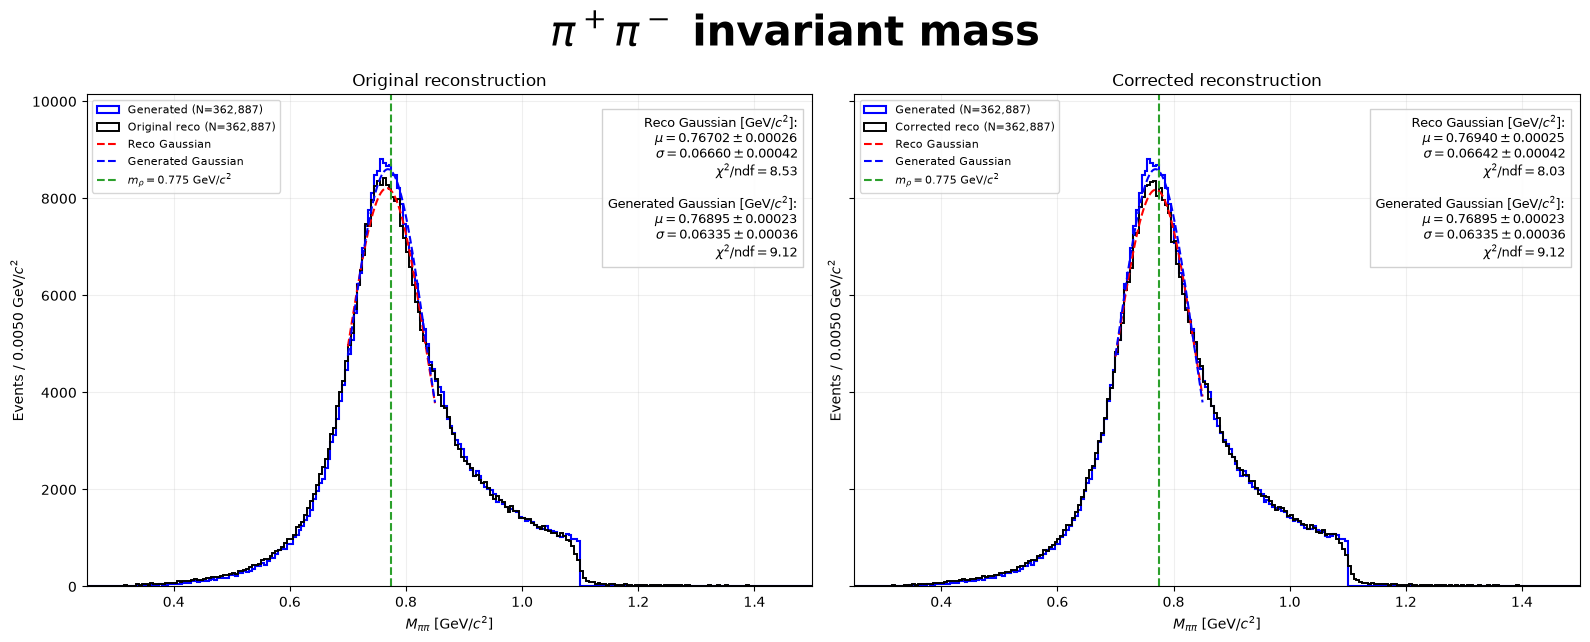

rho, generated: N=362,887; below display=0; above display=0
rho, before: N=362,887; below display=0; above display=299
rho, after: N=362,887; below display=0; above display=309
Rho Gaussian sigma is descriptive, not an intrinsic rho width.


In [108]:
rho_figure = plot_comparison(
    "rho", RHO_BINS, RHO_FIT_RANGE, r"$\pi^+\pi^-$ invariant mass",
    r"$M_{\pi\pi}$ [GeV/$c^2$]", fit_generated=True,
)
print("Rho Gaussian sigma is descriptive, not an intrinsic rho width.")

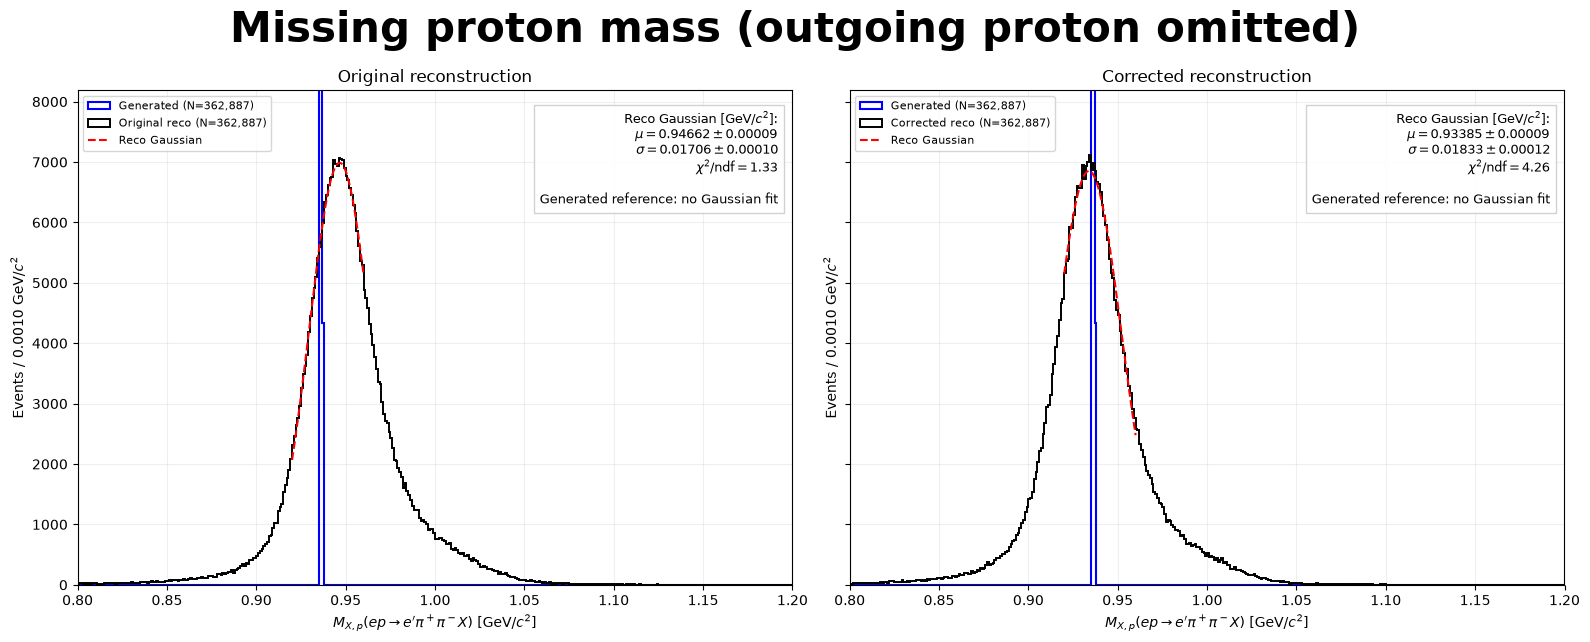

missing_proton, generated: N=362,887; below display=0; above display=0
missing_proton, before: N=362,887; below display=2,952; above display=13
missing_proton, after: N=362,887; below display=3,351; above display=10
Generated missing-proton mass: mean=0.936155521, RMS=0.000405 GeV/c^2; proton mass=0.938272081 GeV/c^2


,observable,state,status,mu,mu_error,sigma,sigma_error,chi2_ndf
0,rho,generated,ok,0.768952,0.000229,0.063351,0.000363,9.120946
1,rho,before,ok,0.767016,0.000261,0.066605,0.000425,8.526108
2,rho,after,ok,0.769402,0.000253,0.066416,0.000422,8.026249
3,missing_proton,generated,not fitted (delta-like reference),NaN,NaN,NaN,NaN,NaN
4,missing_proton,before,ok,0.946619,0.000086,0.017064,0.000099,1.330634
5,missing_proton,after,ok,0.933854,0.000095,0.018332,0.000120,4.257035


Generated missing-proton mean minus physical proton mass: -2.117 MeV/c^2
Large chi2/ndf: Gaussian shape is approximate; covariance errors omit shape/window systematics.
Final verification: 362,887 identical events in each of all six distributions.


In [109]:
missing_figure = plot_comparison(
    "missing_proton", MISSING_BINS, MISSING_FIT_RANGE, "Missing proton mass (outgoing proton omitted)",
    r"$M_{X,p}(ep\rightarrow e'\pi^+\pi^-X)$ [GeV/$c^2$]", fit_generated=False,
)
generated_missing = masses[("missing_proton", "generated")]
print(f"Generated missing-proton mass: mean={generated_missing.mean():.9f}, "
      f"RMS={generated_missing.std():.3g} GeV/c^2; proton mass={MASS_GEV['p']:.9f} GeV/c^2")
fit_summary = pd.DataFrame(fit_records)
with pd.option_context("display.max_columns", None, "display.width", 140):
    display(fit_summary)
print(f"Generated missing-proton mean minus physical proton mass: "
      f"{1000*(generated_missing.mean()-MASS_GEV['p']):+.3f} MeV/c^2")
print("Large chi2/ndf: Gaussian shape is approximate; covariance errors omit shape/window systematics.")
print(f"Final verification: {N_COMMON:,} identical events in each of all six distributions.")

Binning: corrected reconstructed kinematics. One event mask per bin for generated/before/after.
Edges [GeV²]: [ 0.66217423  2.86070813  4.08947246  5.52652668 12.35001053]
Common sample: 362,887; below bin range: 0; above: 0


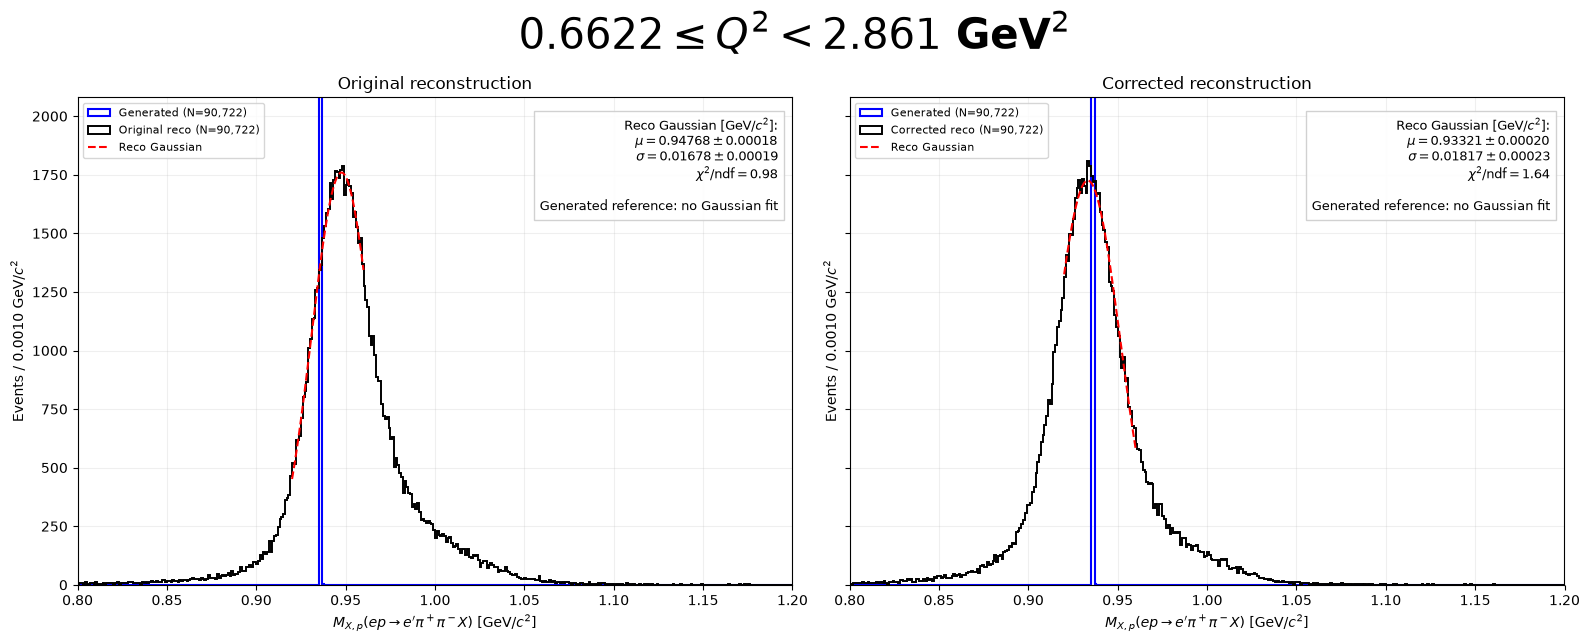

missing_proton, generated: N=90,722; below display=0; above display=0
missing_proton, before: N=90,722; below display=695; above display=5
missing_proton, after: N=90,722; below display=829; above display=5


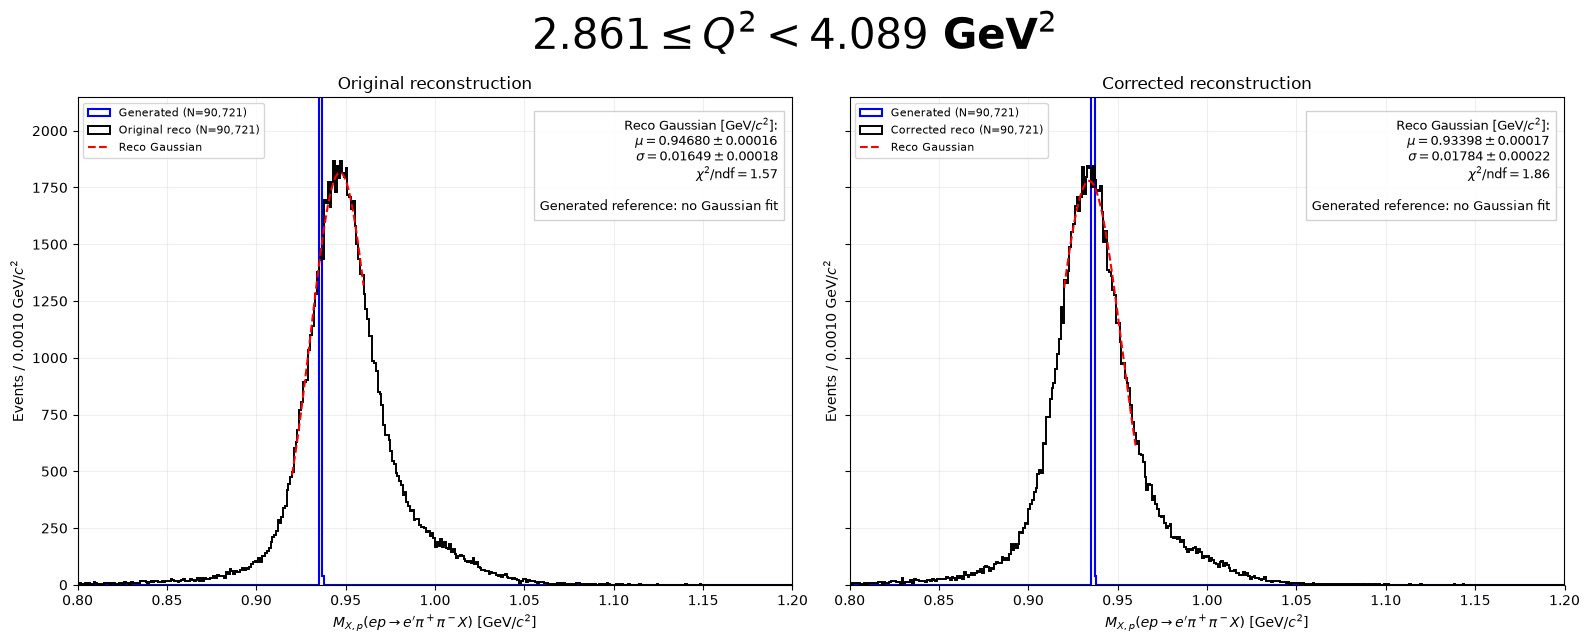

missing_proton, generated: N=90,721; below display=0; above display=0
missing_proton, before: N=90,721; below display=759; above display=2
missing_proton, after: N=90,721; below display=856; above display=1


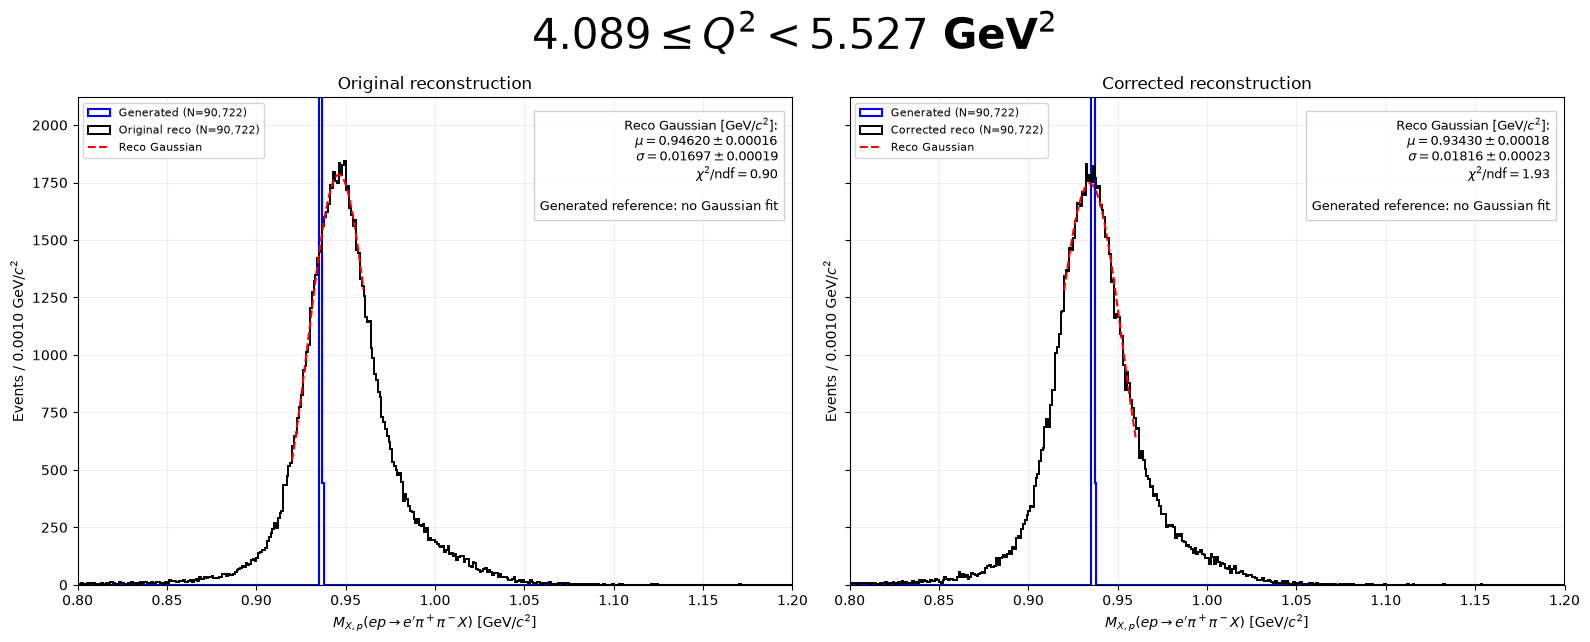

missing_proton, generated: N=90,722; below display=0; above display=0
missing_proton, before: N=90,722; below display=713; above display=1
missing_proton, after: N=90,722; below display=798; above display=0


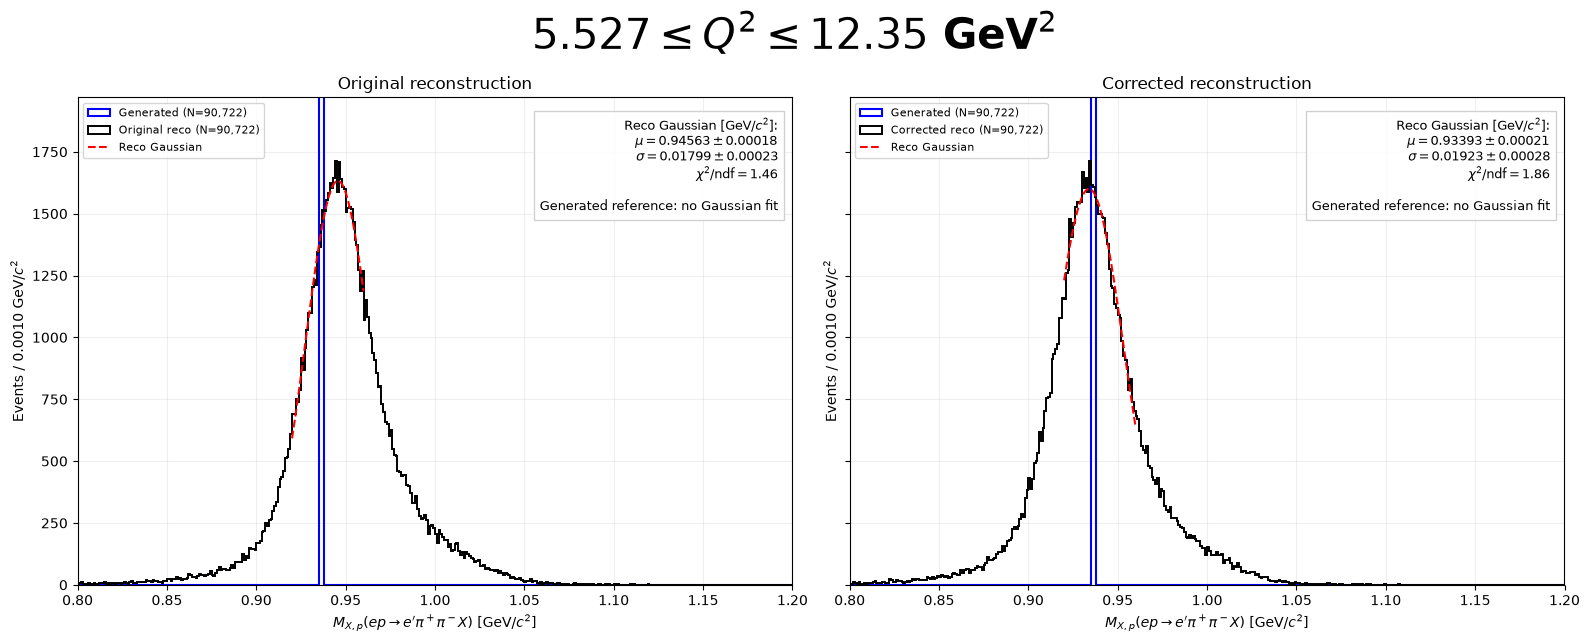

missing_proton, generated: N=90,722; below display=0; above display=0
missing_proton, before: N=90,722; below display=785; above display=5
missing_proton, after: N=90,722; below display=868; above display=4
Confirmed identical event membership and counts within every bin.


,bin,low_GeV2,high_GeV2,generated,before,after
0,1,0.662174,2.860708,90722,90722,90722
1,2,2.860708,4.089472,90721,90721,90721
2,3,4.089472,5.526527,90722,90722,90722
3,4,5.526527,12.350011,90722,90722,90722


,bin,low_GeV2,high_GeV2,binning_state,events,observable,state,status,mu,mu_error,sigma,sigma_error,chi2_ndf
0,1,0.662174,2.860708,after,90722,missing_proton,generated,not fitted (delta-like reference),NaN,NaN,NaN,NaN,NaN
1,1,0.662174,2.860708,after,90722,missing_proton,before,ok,0.947677,0.000184,0.016783,0.000191,0.976774
2,1,0.662174,2.860708,after,90722,missing_proton,after,ok,0.933208,0.000197,0.018174,0.000235,1.639461
3,2,2.860708,4.089472,after,90721,missing_proton,generated,not fitted (delta-like reference),NaN,NaN,NaN,NaN,NaN
4,2,2.860708,4.089472,after,90721,missing_proton,before,ok,0.946796,0.000161,0.016489,0.000178,1.567558
5,2,2.860708,4.089472,after,90721,missing_proton,after,ok,0.933976,0.000175,0.017840,0.000218,1.864241
6,3,4.089472,5.526527,after,90722,missing_proton,generated,not fitted (delta-like reference),NaN,NaN,NaN,NaN,NaN
7,3,4.089472,5.526527,after,90722,missing_proton,before,ok,0.946200,0.000163,0.016968,0.000191,0.897665
8,3,4.089472,5.526527,after,90722,missing_proton,after,ok,0.934298,0.000178,0.018163,0.000232,1.925632
9,4,5.526527,12.350011,after,90722,missing_proton,generated,not fitted (delta-like reference),NaN,NaN,NaN,NaN,NaN


In [110]:

# Proton missing mass in Q² bins.
# Run: Execute this cell in Jupyter after running all preceding cells.
#
# Q² is calculated using corrected reconstructed electron momentum.
# The same event masks are used for generated, before, and after distributions.

Q2_BINNING_STATE = "after"

q2_for_bins = event_kinematics[("Q2", Q2_BINNING_STATE)]

Q2_BIN_EDGES = np.quantile(
    q2_for_bins,
    [0.0, 0.25, 0.50, 0.75, 1.0]
)

# Optional fixed edges:
# Q2_BIN_EDGES = np.array([0., 1., 2., 3., 6.])


def plot_missing_proton_in_bins(values, edges, variable_label, binning_state):

    values = np.asarray(values, dtype=np.float64)
    edges = np.asarray(edges, dtype=np.float64)

    if values.shape != (N_COMMON,) or not np.isfinite(values).all():
        raise ValueError(
            "Binning values must align with every event in the common sample"
        )

    if (
        edges.ndim != 1
        or len(edges) < 2
        or not np.isfinite(edges).all()
        or not (np.diff(edges) > 0).all()
    ):
        raise ValueError(
            "Bin edges must be finite and strictly increasing; "
            "adjust repeated quantiles manually"
        )

    indices = np.searchsorted(edges, values, side="right") - 1

    # Bins are [low, high), except the last bin,
    # which also includes its upper edge.
    indices[values == edges[-1]] = len(edges) - 2

    underflow = int(np.count_nonzero(values < edges[0]))
    overflow = int(np.count_nonzero(values > edges[-1]))

    state_label = {
        "before": "original reconstructed",
        "after": "corrected reconstructed",
        "generated": "generated",
    }[binning_state]

    print(
        f"Binning: {state_label} kinematics. "
        "One event mask per bin for generated/before/after."
    )
    print("Edges [GeV²]:", np.array2string(edges, precision=8))
    print(
        f"Common sample: {N_COMMON:,}; "
        f"below bin range: {underflow:,}; "
        f"above: {overflow:,}"
    )

    figures, rows, fit_rows = [], [], []

    for bin_index, (low, high) in enumerate(zip(edges[:-1], edges[1:])):

        mask = indices == bin_index
        n_events = int(mask.sum())

        selected = {
            ("missing_proton", state):
                masses[("missing_proton", state)][mask]
            for state in STATES
        }

        assert all(
            len(array) == n_events
            for array in selected.values()
        )

        rows.append({
            "bin": bin_index + 1,
            "low_GeV2": low,
            "high_GeV2": high,
            **{
                state: len(selected[("missing_proton", state)])
                for state in STATES
            },
        })

        if n_events == 0:
            print(f"Bin {bin_index + 1} is empty; no fit or plot.")
            continue

        right_operator = (
            r"\leq" if bin_index == len(edges) - 2 else "<"
        )

        interval = (
            rf"${low:.4g} \leq {variable_label} "
            rf"{right_operator} {high:.4g}$ GeV$^2$"
        )

        first_fit_record = len(fit_records)

        figure = plot_comparison(
            "missing_proton",
            MISSING_BINS,
            MISSING_FIT_RANGE,
            interval,  # Only the Q² interval appears in the title
            r"$M_{X,p}(ep\rightarrow e'\pi^+\pi^-X)$ [GeV/$c^2$]",
            fit_generated=False,
            selected_masses=selected,
        )

        # Set title font size to 30 pt.
        if figure._suptitle is not None:
            figure._suptitle.set_fontsize(30)

        for ax in figure.axes:
            ax.title.set_fontsize(30)

        figures.append(figure)

        for record in fit_records[first_fit_record:]:
            fit_rows.append({
                "bin": bin_index + 1,
                "low_GeV2": low,
                "high_GeV2": high,
                "binning_state": binning_state,
                "events": n_events,
                **record,
            })

    counts = pd.DataFrame(rows)

    assert (
        int(counts["generated"].sum()) + underflow + overflow
        == N_COMMON
    )

    assert (counts["generated"] == counts["before"]).all()
    assert (counts["generated"] == counts["after"]).all()

    print(
        "Confirmed identical event membership "
        "and counts within every bin."
    )

    display(counts)

    fits = pd.DataFrame(fit_rows)

    with pd.option_context(
        "display.max_columns", None,
        "display.width", 180
    ):
        display(fits)

    return figures, counts, fits


q2_missing_figures, q2_event_counts, q2_fit_summary = (
    plot_missing_proton_in_bins(
        q2_for_bins,
        Q2_BIN_EDGES,
        r"Q^2",
        Q2_BINNING_STATE,
    )
)


Binning: corrected reconstructed kinematics. One event mask per bin for generated/before/after.
Edges [GeV²]: [0.1371448  0.43272865 0.66950776 1.02605112 3.76791848]
Common sample: 362,887; below bin range: 0; above: 0


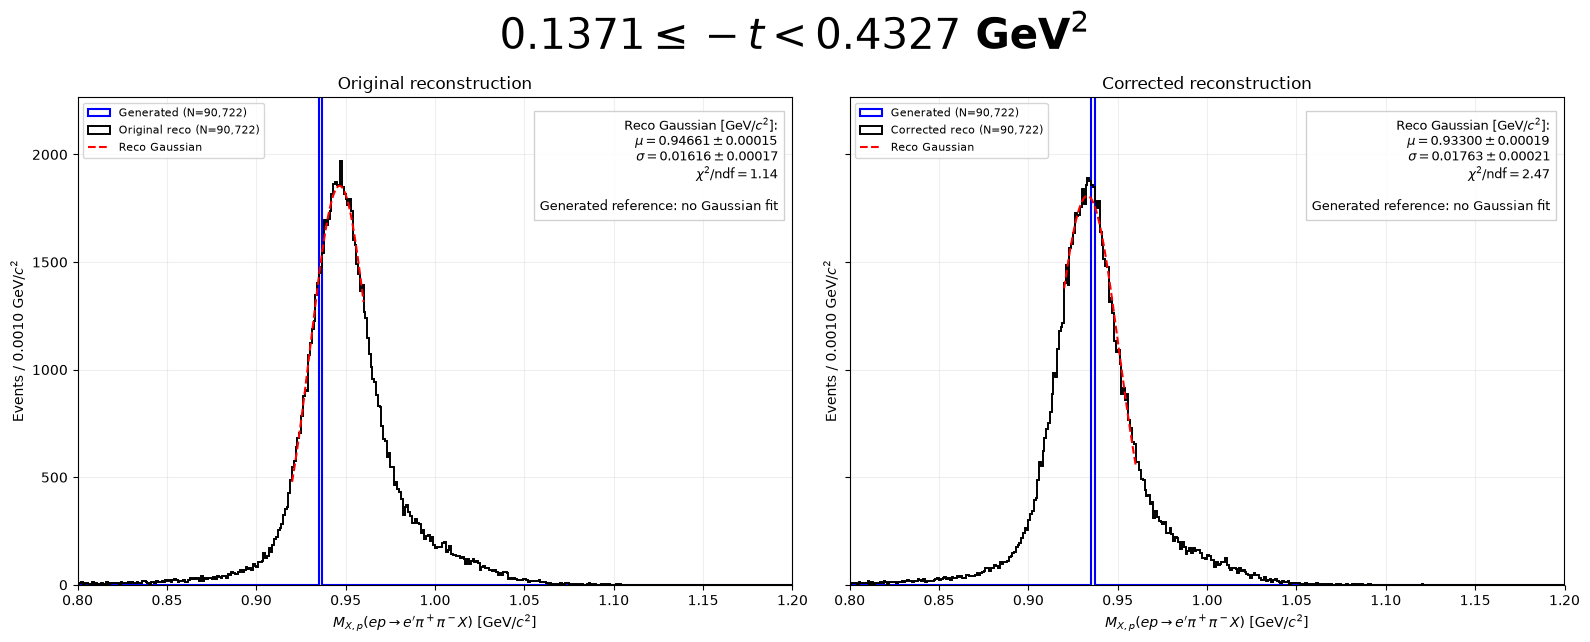

missing_proton, generated: N=90,722; below display=0; above display=0
missing_proton, before: N=90,722; below display=781; above display=0
missing_proton, after: N=90,722; below display=891; above display=0


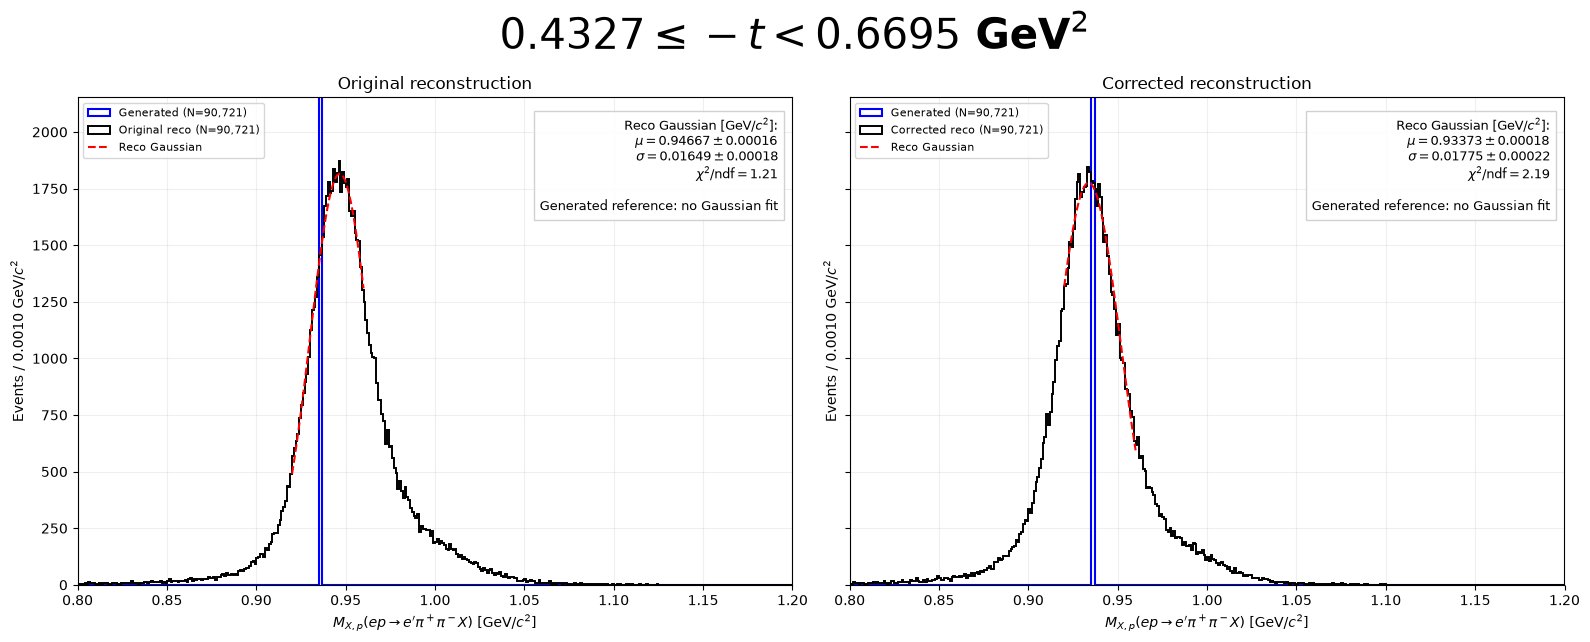

missing_proton, generated: N=90,721; below display=0; above display=0
missing_proton, before: N=90,721; below display=747; above display=1
missing_proton, after: N=90,721; below display=846; above display=1


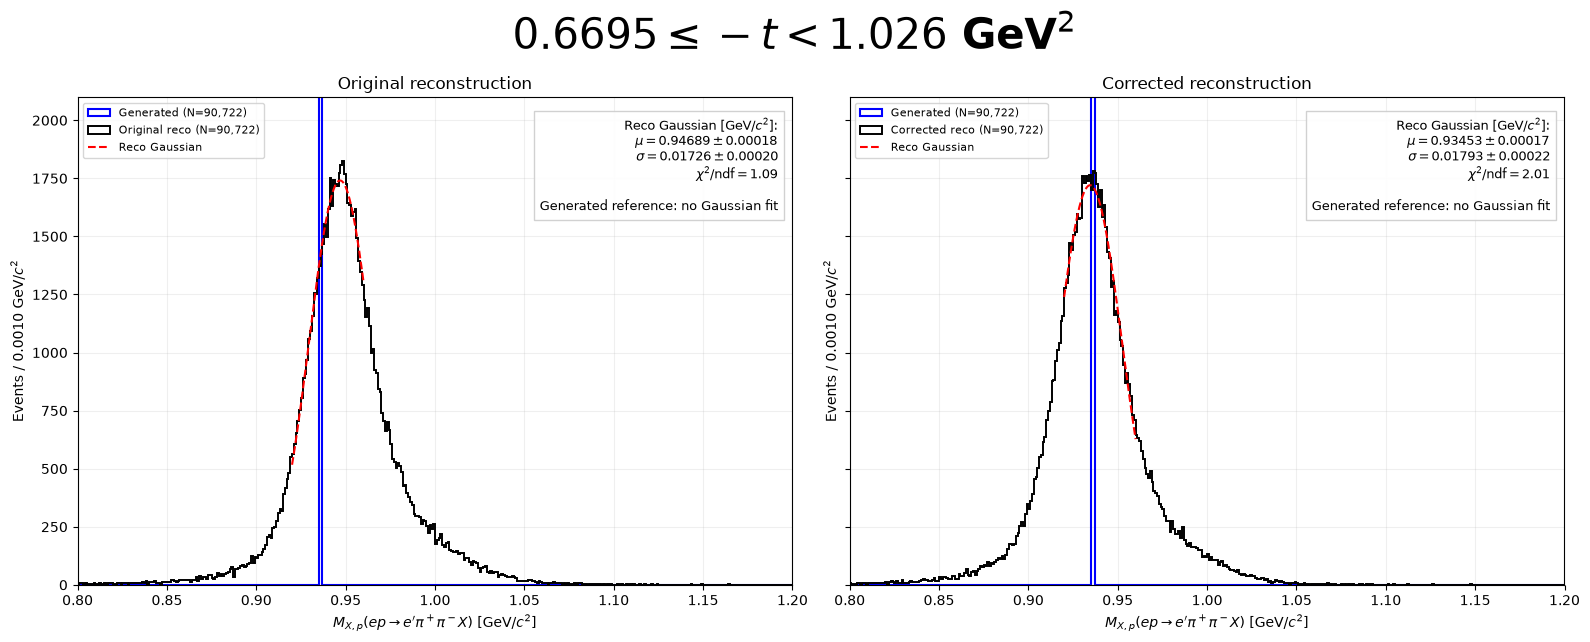

missing_proton, generated: N=90,722; below display=0; above display=0
missing_proton, before: N=90,722; below display=699; above display=2
missing_proton, after: N=90,722; below display=795; above display=2


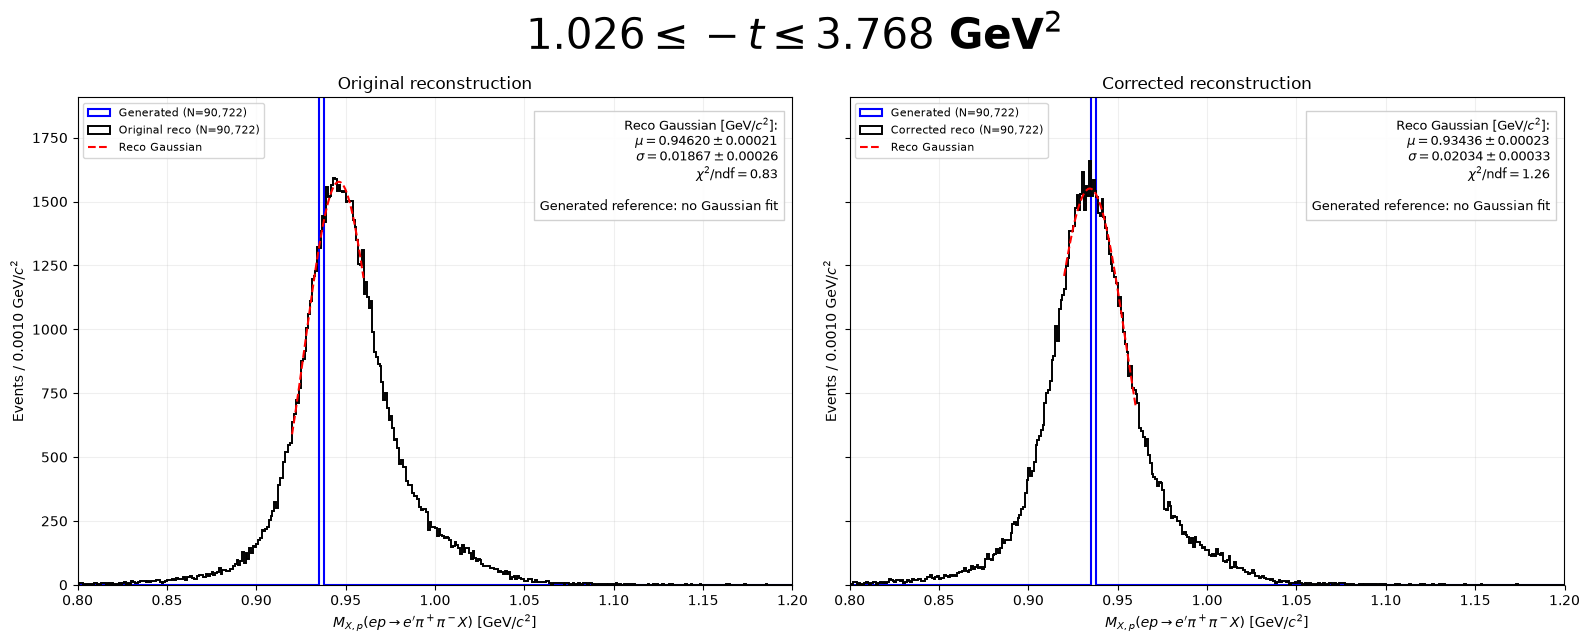

missing_proton, generated: N=90,722; below display=0; above display=0
missing_proton, before: N=90,722; below display=725; above display=10
missing_proton, after: N=90,722; below display=819; above display=7
Confirmed identical event membership and counts within every bin.


,bin,low_GeV2,high_GeV2,generated,before,after
0,1,0.137145,0.432729,90722,90722,90722
1,2,0.432729,0.669508,90721,90721,90721
2,3,0.669508,1.026051,90722,90722,90722
3,4,1.026051,3.767918,90722,90722,90722


,bin,low_GeV2,high_GeV2,binning_state,events,observable,state,status,mu,mu_error,sigma,sigma_error,chi2_ndf
0,1,0.137145,0.432729,after,90722,missing_proton,generated,not fitted (delta-like reference),NaN,NaN,NaN,NaN,NaN
1,1,0.137145,0.432729,after,90722,missing_proton,before,ok,0.946607,0.000152,0.016160,0.000167,1.136208
2,1,0.137145,0.432729,after,90722,missing_proton,after,ok,0.932997,0.000186,0.017627,0.000213,2.467295
3,2,0.432729,0.669508,after,90721,missing_proton,generated,not fitted (delta-like reference),NaN,NaN,NaN,NaN,NaN
4,2,0.432729,0.669508,after,90721,missing_proton,before,ok,0.946671,0.000160,0.016487,0.000178,1.206891
5,2,0.432729,0.669508,after,90721,missing_proton,after,ok,0.933729,0.000177,0.017751,0.000216,2.192689
6,3,0.669508,1.026051,after,90722,missing_proton,generated,not fitted (delta-like reference),NaN,NaN,NaN,NaN,NaN
7,3,0.669508,1.026051,after,90722,missing_proton,before,ok,0.946889,0.000180,0.017256,0.000203,1.092107
8,3,0.669508,1.026051,after,90722,missing_proton,after,ok,0.934528,0.000171,0.017930,0.000225,2.008809
9,4,1.026051,3.767918,after,90722,missing_proton,generated,not fitted (delta-like reference),NaN,NaN,NaN,NaN,NaN


In [111]:
# Proton missing mass in t bins. Run the Q² cell above to define the binning helper.
# t = (P_target - P_p')² = 2*m_p*(m_p-E_p') <= 0 for a stationary proton target.
# Display positive -t, in GeV² (c=1), and use the same fixed event bins before/after.
T_BINNING_STATE = "after"  # Corrected reconstructed momenta (px_rec, py_rec, pz_rec); fixed for all comparisons.
minus_t_for_bins = event_kinematics[("minus_t", T_BINNING_STATE)]
MINUS_T_BIN_EDGES = np.quantile(minus_t_for_bins, [0.0, 0.25, 0.50, 0.75, 1.0])
# Replace with fixed ascending -t edges if desired; any out-of-range events are reported.

t_missing_figures, t_event_counts, t_fit_summary = plot_missing_proton_in_bins(
    minus_t_for_bins, MINUS_T_BIN_EDGES, r"-t", T_BINNING_STATE,
)

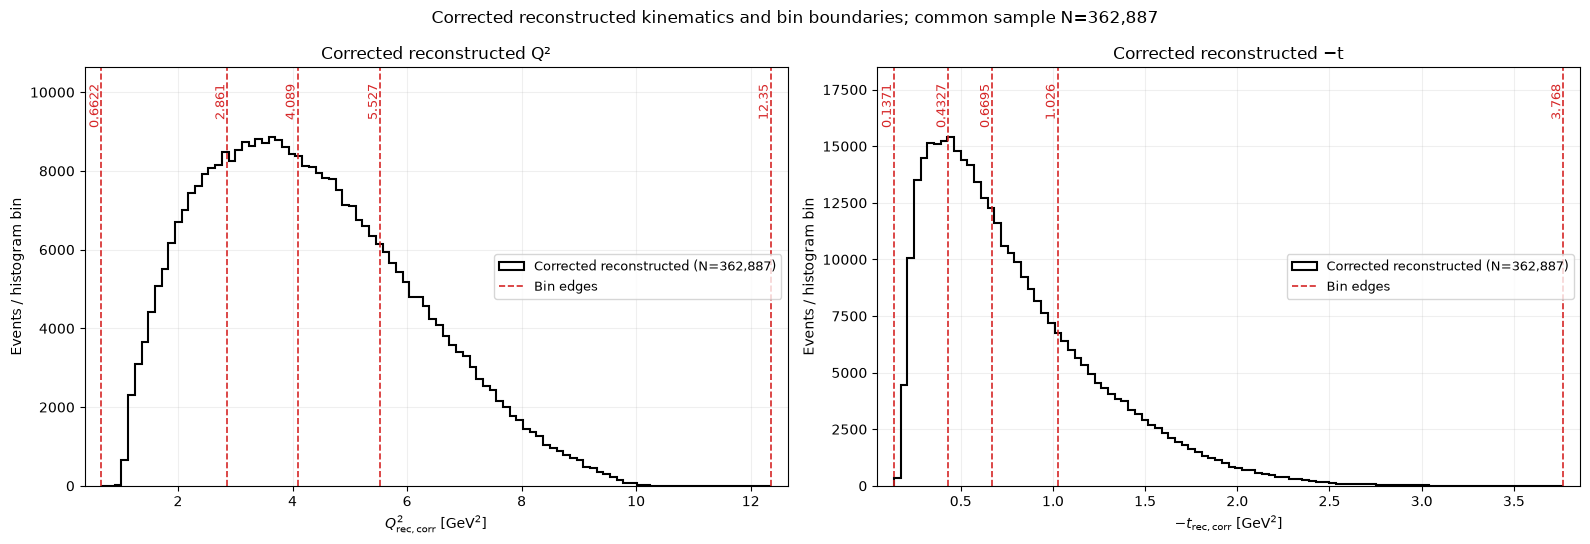

,edge,Q2_corrected_rec_GeV2,minus_t_corrected_rec_GeV2
0,0,0.662174,0.137145
1,1,2.860708,0.432729
2,2,4.089472,0.669508
3,3,5.526527,1.026051
4,4,12.350011,3.767918


In [99]:
# Corrected reconstructed Q² and -t distributions with the exact edges used in the two cells above.
# Both use corrected px_rec, py_rec, pz_rec on the common event sample.
assert Q2_BINNING_STATE == T_BINNING_STATE == "after", "Rerun both binning cells with corrected reconstructed kinematics"
kinematic_distributions_figure, kinematic_axes = plt.subplots(1, 2, figsize=(16, 5.5))
for ax, values, edges, xlabel, title in [
    (kinematic_axes[0], q2_for_bins, Q2_BIN_EDGES,
     r"$Q^2_{\mathrm{rec,corr}}$ [GeV$^2$]", "Corrected reconstructed Q²"),
    (kinematic_axes[1], minus_t_for_bins, MINUS_T_BIN_EDGES,
     r"$-t_{\mathrm{rec,corr}}$ [GeV$^2$]", "Corrected reconstructed −t"),
]:
    assert len(values) == N_COMMON and np.isfinite(values).all()
    counts, _, _ = ax.hist(values, bins=100, histtype="step", color="black", linewidth=1.5,
                           label=f"Corrected reconstructed (N={N_COMMON:,})")
    for edge_index, edge in enumerate(edges):
        ax.axvline(edge, color="tab:red", linestyle="--", linewidth=1.2,
                   label="Bin edges" if edge_index == 0 else None)
        ax.text(edge, 0.96, f" {edge:.4g}", transform=ax.get_xaxis_transform(),
                rotation=90, va="top", ha="right", color="tab:red", fontsize=9)
    low, high = min(values.min(), edges[0]), max(values.max(), edges[-1])
    padding = max(0.025 * (high - low), 1e-6)
    ax.set(xlabel=xlabel, ylabel="Events / histogram bin", title=title,
           xlim=(low-padding, high+padding), ylim=(0, 1.20 * max(counts.max(), 1)))
    ax.set_yscale("linear")
    ax.legend(loc="center right", fontsize=9)
    ax.grid(alpha=0.2)
kinematic_distributions_figure.suptitle(f"Corrected reconstructed kinematics and bin boundaries; common sample N={N_COMMON:,}")
kinematic_distributions_figure.tight_layout()
plt.show()
display(pd.DataFrame({"edge": np.arange(len(Q2_BIN_EDGES)),
                      "Q2_corrected_rec_GeV2": Q2_BIN_EDGES, "minus_t_corrected_rec_GeV2": MINUS_T_BIN_EDGES}))

/var/folders/yb/f9___dg10vn7vg_y7r3q16w80000gp/T/ipykernel_32128/1158129764.py:75: DeprecationWarning: fetch_record_batch() is deprecated, use to_arrow_reader() instead.
  reader = rho_con.execute(electron_query).fetch_record_batch(


EVENT SELECTION
Electron:
  pid_gen = 11
  reconstructed = 1
  detector = 1 (FD)
  was_corrected = 1
  p_rec <= 2.0 GeV/c

Required in the same event:
  pi+    reconstructed = 1
  pi-    reconstructed = 1
  proton reconstructed = 1

RESULTS
Selected electron rows: 363,619
Finite Q2 entries:      363,619
Nonfinite momentum excluded: 0
Nonfinite Q2 excluded: 0
Negative Q2: 0
Q2 below display: 0; above display: 0
Mean Q2: 4.294164 GeV2


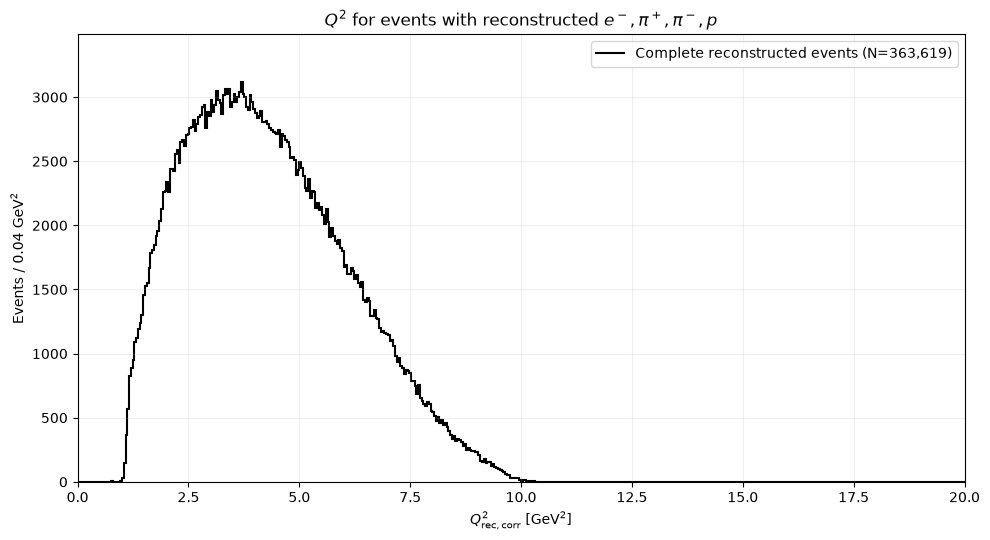

In [100]:

# Run: Execute this cell in validate_rho_and_missing_mass.ipynb
# after running the notebook's setup and kinematics cells.
#
# Select corrected FD electrons only from events where the
# electron, pi+, pi-, and proton were all reconstructed.
#
# Keep the previously requested electron momentum cut: p_rec <= 2 GeV/c.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ALL_FD_ELECTRON_Q2_BINS = np.linspace(0.0, 20.0, 501)

all_fd_electron_q2_counts = np.zeros(
    len(ALL_FD_ELECTRON_Q2_BINS) - 1, dtype=np.int64
)

all_fd_electron_selected_rows = 0
all_fd_electron_nonfinite_momentum = 0
all_fd_electron_nonfinite_q2 = 0
all_fd_electron_negative_q2 = 0
all_fd_electron_q2_underflow = 0
all_fd_electron_q2_overflow = 0
all_fd_electron_finite_q2 = 0
all_fd_electron_q2_sum = 0.0


# ----------------------------------------------------------
# Event selection:
# Require reconstructed pi+, pi-, and proton in the same event.
#
# Use (file_id, event) as the unique event identifier.
# Hadrons only need reconstructed=1, NOT was_corrected=1.
# ----------------------------------------------------------

electron_query = f"""
WITH complete_hadron_events AS (
    SELECT file_id, event
    FROM {source_sql}
    WHERE pid_gen IN (211, -211, 2212)
      AND reconstructed = 1
      AND detector = 1
      AND was_corrected = 1
    GROUP BY file_id, event
    HAVING COUNT(DISTINCT pid_gen) = 3
)

SELECT
    e.px_rec,
    e.py_rec,
    e.pz_rec

FROM {source_sql} AS e

INNER JOIN complete_hadron_events AS h
    USING (file_id, event)

WHERE e.pid_gen = 11
  AND e.reconstructed = 1
  AND e.detector = 1
  AND e.was_corrected = 1
  AND e.p_rec >= 2.0
"""

# Stream the selected electrons rather than loading
# the complete Parquet dataset into Python memory.
# Run: Execute this cell in Jupyter after the notebook's setup cells.
# Create a fresh DuckDB connection for this analysis.

import duckdb

rho_con = duckdb.connect(database=":memory:")

reader = rho_con.execute(electron_query).fetch_record_batch(
    rows_per_batch=250_000
)

for batch in reader:

    all_fd_electron_selected_rows += len(batch)

    px_e, py_e, pz_e = [
        batch.column(i).to_numpy(
            zero_copy_only=False
        ).astype(np.float64)
        for i in range(3)
    ]

    finite_momentum = (
        np.isfinite(px_e)
        & np.isfinite(py_e)
        & np.isfinite(pz_e)
    )

    all_fd_electron_nonfinite_momentum += int(
        np.count_nonzero(~finite_momentum)
    )

    q2_e = electron_q2_from_components(
        px_e[finite_momentum],
        py_e[finite_momentum],
        pz_e[finite_momentum],
    )

    finite_q2 = np.isfinite(q2_e)

    all_fd_electron_nonfinite_q2 += int(
        np.count_nonzero(~finite_q2)
    )

    q2_e = q2_e[finite_q2]

    all_fd_electron_finite_q2 += len(q2_e)
    all_fd_electron_q2_sum += q2_e.sum()

    all_fd_electron_negative_q2 += int(
        np.count_nonzero(q2_e < 0)
    )

    all_fd_electron_q2_underflow += int(
        np.count_nonzero(
            q2_e < ALL_FD_ELECTRON_Q2_BINS[0]
        )
    )

    all_fd_electron_q2_overflow += int(
        np.count_nonzero(
            q2_e > ALL_FD_ELECTRON_Q2_BINS[-1]
        )
    )

    counts, _ = np.histogram(
        q2_e,
        bins=ALL_FD_ELECTRON_Q2_BINS
    )

    all_fd_electron_q2_counts += counts


# ----------------------------------------------------------
# Validation and statistics
# ----------------------------------------------------------

assert (
    all_fd_electron_finite_q2
    + all_fd_electron_nonfinite_q2
    + all_fd_electron_nonfinite_momentum
    == all_fd_electron_selected_rows
)

assert (
    int(all_fd_electron_q2_counts.sum())
    + all_fd_electron_q2_underflow
    + all_fd_electron_q2_overflow
    == all_fd_electron_finite_q2
)

print("=" * 65)
print("EVENT SELECTION")
print("=" * 65)

print("Electron:")
print("  pid_gen = 11")
print("  reconstructed = 1")
print("  detector = 1 (FD)")
print("  was_corrected = 1")
print("  p_rec <= 2.0 GeV/c")

print("\nRequired in the same event:")
print("  pi+    reconstructed = 1")
print("  pi-    reconstructed = 1")
print("  proton reconstructed = 1")

print("\nRESULTS")
print(f"Selected electron rows: {all_fd_electron_selected_rows:,}")
print(f"Finite Q2 entries:      {all_fd_electron_finite_q2:,}")

print(
    f"Nonfinite momentum excluded: "
    f"{all_fd_electron_nonfinite_momentum:,}"
)
print(
    f"Nonfinite Q2 excluded: "
    f"{all_fd_electron_nonfinite_q2:,}"
)
print(
    f"Negative Q2: {all_fd_electron_negative_q2:,}"
)
print(
    f"Q2 below display: {all_fd_electron_q2_underflow:,}; "
    f"above display: {all_fd_electron_q2_overflow:,}"
)

if all_fd_electron_finite_q2:
    print(
        f"Mean Q2: "
        f"{all_fd_electron_q2_sum / all_fd_electron_finite_q2:.6f} GeV2"
    )

print("=" * 65)


# ----------------------------------------------------------
# Plot Q2 distribution
# ----------------------------------------------------------

fig, ax = plt.subplots(figsize=(10, 5.5))

ax.stairs(
    all_fd_electron_q2_counts,
    ALL_FD_ELECTRON_Q2_BINS,
    color="black",
    linewidth=1.5,
    label=f"Complete reconstructed events (N={all_fd_electron_finite_q2:,})",
)

ax.set(
    xlabel=r"$Q^2_{\mathrm{rec,corr}}$ [GeV$^2$]",
    ylabel="Events / 0.04 GeV$^2$",
    title=r"$Q^2$ for events with reconstructed $e^-,\pi^+,\pi^-,p$",
    xlim=(0, 20),
    ylim=(0, 1.12 * max(all_fd_electron_q2_counts.max(), 1)),
)

ax.set_yscale("linear")
ax.legend(loc="upper right")
ax.grid(alpha=0.2)

fig.tight_layout()
plt.show()
